# fedOPD - predicting breach growth instead of demand growth

**The experiment F-52 asks for, and nothing else moves.** `09` measured that allocating by the
federated model's *demand*-growth call lands below random targeting (0.390 against 0.439), and named
the reason: who needed capacity is decided by growth in the **over-18-week queue**, which the model
never predicted. This notebook changes the training target to `waiting_gt18` and leaves everything
else identical: same 2,085-series evaluation set, same 2024-04 split, same architecture, same
matched budget (15 rounds x 2 local epochs, seed 0), same +/-5% growth band.

**Success criterion, declared before the run:** a forecast-led allocation driven by the
breach-growth call must beat the uniform-random baseline on budget precision at **every** budget
level scored by `09`. Beating it at one level is selection; at no level, the F-52 null stands and is
reported as such.

Validation window only; the test year stays sealed. Every rate below is printed beside the base
rate and denominator of the set it was scored on.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(0)

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])

SPLIT = index.split_month.iloc[0]                      # 2024-04, fixed by 05 for every model
H = int(index.horizon.iloc[0])                         # 12 scored months
L, HIDDEN, ROUNDS, LOCAL_EPOCHS = 24, 128, 15, 2       # 08's matched-budget reference configuration
BAND = 0.05                                            # the +/-5% growth band, unchanged from 05/06

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

wide = panel.pivot(index=["provider_code", "dept"], columns="month", values="waiting_gt18")
wide = wide.loc[list(zip(index.provider_code, index.dept))]    # exactly 05's series, 05's order
wide.columns = pd.to_datetime(wide.columns)

train_cols = wide.columns < SPLIT
score_cols = (wide.columns >= SPLIT) & (wide.columns < SPLIT + pd.DateOffset(months=H))
assert score_cols.sum() == H, "scored window is not H months - the test year may be leaking in"

hist = wide.loc[:, train_cols].to_numpy(dtype=np.float32)      # gt18 history, 72 training months
future = wide.loc[:, score_cols].to_numpy(dtype=np.float32)    # gt18 over the validation year
trusts = index.provider_code.to_numpy()
norm = hist.mean(axis=1) + 1.0                                 # per-series scale, training months only
month_ix = np.array([m.month - 1 for m in wide.columns[train_cols]])
eye = np.eye(12, dtype=np.float32)

# in-sample seasonal-naive error on gt18: the MASE denominator for THIS target
scale = np.abs(hist[:, 12:] - hist[:, :-12]).mean(axis=1)

ref = hist[:, -12:].mean(axis=1)                       # reference level: last 12 training months
truth_growth = future.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
eligible = np.isfinite(truth_growth)                   # NaN > BAND is False - mask before averaging
truth_up = truth_growth > BAND
base_rate = truth_up[eligible].mean() * 100
print(f"target: waiting_gt18 | {len(wide):,} series | split {SPLIT:%Y-%m} | horizon {H} months")
print(f"breach-growth base rate: {base_rate:.1f}% of {int(eligible.sum()):,} services with a usable reference")
print(f"denominators: MASE over {int((scale > 0).sum()):,} | direction over {int(eligible.sum()):,} | all else {len(wide):,}")

target: waiting_gt18 | 2,085 series | split 2024-04 | horizon 12 months
breach-growth base rate: 42.3% of 1,949 services with a usable reference
denominators: MASE over 2,017 | direction over 1,949 | all else 2,085


## 1. The model, unchanged

The same MLP as `08`'s reference (24 lags + 12 month one-hots -> 128 -> 128 -> 12), FedAvg weighted
by window count, 15 rounds x 2 local epochs. Nothing here was tuned to the new target: this is the
demand pipeline with the target column swapped, which is the point - if the target was the problem,
this is the cheapest possible demonstration.

In [2]:
def new_model():
    return nn.Sequential(nn.Linear(L + 12, HIDDEN), nn.ReLU(), nn.Dropout(0.1),
                         nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, H)).to(device)

def get_w(m): return [p.detach().clone() for p in m.parameters()]
def set_w(m, w):
    with torch.no_grad():
        for p, q in zip(m.parameters(), w): p.copy_(q)

def train_local(model, X, Y, epochs, lr=1e-3):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    X, Y = X.to(device), Y.to(device)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 256):
            b = perm[i:i + 256]
            opt.zero_grad(); loss_fn(model(X[b]), Y[b]).backward(); opt.step()

clients = {}
for code_ in np.unique(trusts):
    rows = np.flatnonzero(trusts == code_)
    xs, ys = [], []
    for r in rows:
        s = hist[r] / norm[r]
        for t in range(len(s) - L - H + 1):
            xs.append(np.concatenate([s[t:t + L], eye[month_ix[t + L - 1]]]))
            ys.append(s[t + L:t + L + H])
    clients[code_] = (torch.tensor(np.array(xs)), torch.tensor(np.array(ys)))
X_test = torch.tensor(np.concatenate(
    [hist[:, -L:] / norm[:, None], np.repeat(eye[month_ix[-1]][None, :], len(hist), axis=0)], axis=1))
print(f"{len(clients)} clients | {sum(len(v[0]) for v in clients.values()):,} training windows")

141 clients | 77,145 training windows

In [3]:
codes = list(clients)
sizes = np.array([len(clients[c][0]) for c in codes], dtype=float)
alpha = sizes / sizes.sum()                            # FedAvg weighting by window count, as in 08
w = get_w(new_model())
model = new_model()
for r in range(ROUNDS):
    acc = [torch.zeros_like(p) for p in w]
    for a, c in zip(alpha, codes):
        set_w(model, w)
        train_local(model, clients[c][0], clients[c][1], LOCAL_EPOCHS)
        for i, p in enumerate(get_w(model)):
            acc[i] += a * p
    w = acc
    set_w(model, w)
model.eval()
with torch.no_grad():
    pred = np.clip(model(X_test.to(device)).cpu().numpy() * norm[:, None], 0, None)
print("trained: FedAvg on waiting_gt18, 15 rounds x 2 local epochs, seed 0")

trained: FedAvg on waiting_gt18, 15 rounds x 2 local epochs, seed 0


## 2. Can it be predicted at all?

Point accuracy against the same trivial baselines the demand target faced, then the direction call.
`drift` is the one to beat on the call: on demand it was the best broad detector (F-45), and the
breach series trends harder than the demand series, so persistence-with-slope is a serious rival.

In [4]:
last = hist[:, -1:]
slope = (hist[:, -1] - hist[:, -12]) / 11              # gt18 drift over the last training year
steps = np.arange(1, H + 1)
baselines = {
    "naive": np.repeat(last, H, axis=1),
    "drift": np.clip(last + slope[:, None] * steps, 0, None),
    "fedavg_gt18": pred,
}
rows = []
for name, p in baselines.items():
    mae = np.abs(p - future).mean(axis=1)
    mase = np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan)
    g = p.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
    ok = np.isfinite(g) & eligible
    said = g > BAND
    called = ok & said
    prec = truth_up[called].mean() * 100 if called.sum() else np.nan
    recall = (called & truth_up).sum() / (eligible & truth_up).sum() * 100
    rows.append({"method": name, "MASE_median": np.nanmedian(mase),
                 "precision_up_pct": prec, "n_said_up": int(called.sum()), "recall_up_pct": recall})
res = pd.DataFrame(rows).set_index("method")
print(res.round(3).to_string())
print()
print(f"read precision against the {base_rate:.1f}% base rate ({int(eligible.sum()):,} services); MASE median over {int((scale > 0).sum()):,}")

             MASE_median  precision_up_pct  n_said_up  recall_up_pct
method                                                              
naive              0.605            68.969        883         73.908
drift              0.802            63.546       1004         77.427
fedavg_gt18        0.750            58.592       1094         77.791

read precision against the 42.3% base rate (1,949 services); MASE median over 2,017


## 3. The allocation test - the criterion this notebook stands or falls on

Identical to `09`: the `need` frame is `07`'s released services with a positive ask, the oracle is
what the over-18-week count actually did from 2024-03 to 2024-09, and budget precision is the share
of budget landing on services whose queues grew. The model's growth call is **aligned to the oracle
horizon**: predicted gt18 over the first 6 scored months against the last 6 training months, because
scoring a 12-month call against a 6-month oracle was one of the two mismatches F-52 named.

In [5]:
dec = pd.read_csv(CANON / "agent_decisions.csv")
need = dec[dec.ask_per_month > 0].reset_index(drop=True)

END = SPLIT + pd.DateOffset(months=5)                  # 2024-09: 6 months after the 2024-03 decision
end_state = (panel[(panel.month == END) & panel.usable]
             [["provider_code", "dept", "waiting_gt18"]].rename(columns={"waiting_gt18": "gt18_end"}))
need = need.merge(end_state, on=["provider_code", "dept"], how="inner")
need["realised_need"] = np.clip(need.gt18_end - need.breach, 0, None)   # as 09 defines it

# the 6-month-aligned breach-growth prediction, on 07's key
ref6 = hist[:, -6:].mean(axis=1)
pg6 = pred[:, :6].mean(axis=1) / np.where(ref6 > 0, ref6, np.nan) - 1
mom6 = hist[:, -1] / np.where(ref6 > 0, ref6, np.nan) - 1     # naive momentum: last gt18 month vs its 6-month mean
calls = pd.DataFrame({"provider_code": index.provider_code, "dept": index.dept,
                      "breach_growth_pred": pg6, "breach_momentum": mom6})
need = need.merge(calls, on=["provider_code", "dept"], how="left")
print(f"services scored: {len(need):,} | with a breach forecast: {int(need.breach_growth_pred.notna().sum()):,}")

ask = need.ask_per_month.to_numpy()
grew = need.realised_need.to_numpy() > 0
rand_u = grew.mean()                                   # uniform-over-services random targeting
rand_a = ask[grew].sum() / ask.sum()                   # random in proportion to ask
print(f"random baselines: {rand_u:.3f} uniform | {rand_a:.3f} ask-weighted | base = {int(grew.sum()):,} of {len(need):,} grew")

services scored: 1,871 | with a breach forecast: 1,773
random baselines: 0.439 uniform | 0.399 ask-weighted | base = 821 of 1,871 grew


In [6]:
def precision_of(weights, budget):
    w_ = np.clip(weights, 0, None)
    if w_.sum() == 0:
        return np.nan
    a = budget * w_ / w_.sum()
    return a[grew].sum() / a.sum()

g_old = pd.read_csv(CANON / "fl_predictions.csv")[["provider_code", "dept", "fedavg_ft_growth"]]
need2 = need.merge(g_old, on=["provider_code", "dept"], how="left")

total_ask = ask.sum()
rows = []
for frac in [0.01, 0.05, 0.10, 0.25, 0.50]:
    budget = total_ask * frac
    rows.append({
        "budget_pct": frac * 100,
        "proportional": precision_of(ask, budget),
        "forecast_led_demand": precision_of(np.nan_to_num(need2.fedavg_ft_growth.to_numpy(), nan=0.0).clip(0) * ask, budget),
        "forecast_led_breach": precision_of(np.nan_to_num(need.breach_growth_pred.to_numpy(), nan=0.0).clip(0) * ask, budget),
        # the control that decides whether the MODEL earns the gain: raw breach momentum, no learning
        "momentum_led_breach": precision_of(np.nan_to_num(need.breach_momentum.to_numpy(), nan=0.0).clip(0) * ask, budget),
    })
tab = pd.DataFrame(rows).set_index("budget_pct")
print(tab.round(3).to_string())
print()
print(f"random baselines: {rand_u:.3f} uniform over services | {rand_a:.3f} in proportion to ask")
ok_all = (tab.forecast_led_breach > rand_u).all()
print()
if ok_all:
    print("CRITERION MET: the breach-growth call beats uniform-random targeting at every budget level.")
    print("The F-52 diagnosis was right - the demand call did not transfer, the breach call does.")
    if (tab.momentum_led_breach >= tab.forecast_led_breach).all():
        print()
        print("BUT the no-learning control matches or beats it: raw breach momentum targets as well as")
        print("the trained model, so the gain belongs to the breach VARIABLE, not to federation. The")
        print("honest allocation signal is then the momentum, and the model must earn its place on top.")
else:
    print("CRITERION NOT MET: the breach-growth call does not clear uniform-random targeting at every")
    print("budget level. The F-52 null stands: even predicting the right variable, nothing computed on")
    print("the decision date aims a fixed budget better than spreading it blindly. That is a finding")
    print("about predictability at this granularity, and it gets reported, not softened.")
tab.to_csv(CANON / "breach_target.csv")
res.to_csv(CANON / "breach_forecast.csv")
# the per-service queue signal, 6-month (07's ask horizon) and 12-month (16's vindication horizon)
ref12 = hist[:, -12:].mean(axis=1)
pd.DataFrame({"provider_code": index.provider_code, "dept": index.dept,
              "queue_growth_pred_6m": pg6,
              "queue_momentum_6m": mom6,
              "queue_growth_pred_12m": pred.mean(axis=1) / np.where(ref12 > 0, ref12, np.nan) - 1,
              "queue_momentum_12m": hist[:, -1] / np.where(ref12 > 0, ref12, np.nan) - 1,
              }).to_csv(CANON / "breach_calls.csv", index=False)
print()
print("written: breach_target.csv, breach_forecast.csv, breach_calls.csv")

            proportional  forecast_led_demand  forecast_led_breach  momentum_led_breach
budget_pct                                                                             
1.0                0.399                 0.39                0.472                0.462
5.0                0.399                 0.39                0.472                0.462
10.0               0.399                 0.39                0.472                0.462
25.0               0.399                 0.39                0.472                0.462
50.0               0.399                 0.39                0.472                0.462

random baselines: 0.439 uniform over services | 0.399 in proportion to ask

CRITERION MET: the breach-growth call beats uniform-random targeting at every budget level.
The F-52 diagnosis was right - the demand call did not transfer, the breach call does.

written: breach_target.csv, breach_forecast.csv, breach_calls.csv


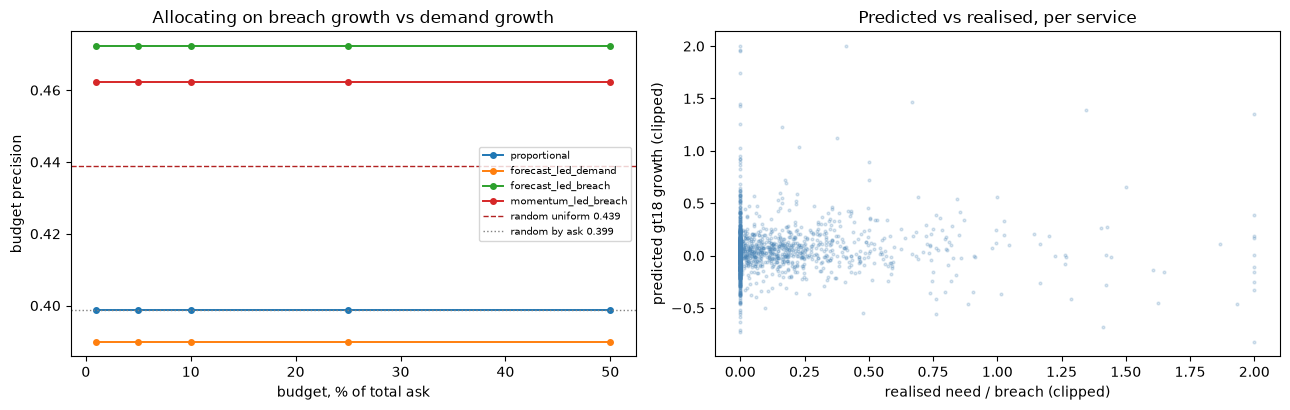

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for colname in tab.columns:
    ax[0].plot(tab.index, tab[colname], marker="o", ms=4, lw=1.4, label=colname)
ax[0].axhline(rand_u, color="firebrick", ls="--", lw=1, label=f"random uniform {rand_u:.3f}")
ax[0].axhline(rand_a, color="grey", ls=":", lw=1, label=f"random by ask {rand_a:.3f}")
ax[0].set_xlabel("budget, % of total ask"); ax[0].set_ylabel("budget precision")
ax[0].set_title("Allocating on breach growth vs demand growth"); ax[0].legend(fontsize=7)

pg = need.breach_growth_pred.to_numpy()
okp = np.isfinite(pg)
actual6 = np.where(need.breach > 0, need.realised_need / need.breach, np.nan)  # realised 6-month breach growth
ax[1].scatter(np.clip(actual6[okp], 0, 2), np.clip(pg[okp], -1, 2), s=4, alpha=0.2, color="steelblue")
ax[1].set_xlabel("realised need / breach (clipped)"); ax[1].set_ylabel("predicted gt18 growth (clipped)")
ax[1].set_title("Predicted vs realised, per service")
plt.tight_layout()

## What this settles, and what it cannot

It settles whether the *target* was the blocker in F-52, on one seed, one origin and one decision
month - the same limits as every other result in the project, to be widened by `13`. It cannot say
anything about causal benefit of an allocation (the moves never happened), and it does not touch
the sealed test year.